# SentinelML: Login Anomaly Detector

Unsupervised anomaly detection on user login logs using an Isolation Forest. Built as an introductory ML project for cybersecurity.

In [1]:
import random
from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
random.seed(42)

## Step 1: Synthetic Dataset Generation

Generate normal daily login events for 30 users, then inject three common anomaly patterns:
- impossible travel (login from an overseas location right after a domestic login)
- brute force bursts (many failed login attempts in a row)
- off-hours logins (middle of the night from unfamiliar locations)

In [2]:
def generate_normal_logins(num_users=30, events_per_user=50):
    locations = ["Dallas_US", "Austin_US", "Houston_US", "NewYork_US", "SanFrancisco_US", "Chicago_US"]
    devices = ["MacOS_Laptop", "Windows_PC", "iPhone_Mobile", "Android_Mobile"]
    
    user_profiles = {
        f"USR_{i:03d}": {
            "home": random.choice(locations),
            "device": random.choice(devices)
        }
        for i in range(1, num_users + 1)
    }
    
    rows = []
    start_time = datetime(2026, 9, 1, 8, 0)
    
    for user_id, profile in user_profiles.items():
        t = start_time + timedelta(hours=random.randint(0, 24))
        for _ in range(events_per_user):
            t += timedelta(hours=random.uniform(4, 36))
            # work hours clustered around daytime
            work_hour = int(np.clip(np.random.normal(13, 3), 7, 20))
            ts = t.replace(hour=work_hour, minute=random.randint(0, 59))
            
            loc = profile["home"] if random.random() < 0.95 else random.choice(locations)
            dev = profile["device"] if random.random() < 0.90 else random.choice(devices)
            failed = 0 if random.random() < 0.90 else 1
            
            rows.append({
                "timestamp": ts,
                "user_id": user_id,
                "location": loc,
                "device_type": dev,
                "login_success": failed <= 1,
                "failed_attempts": failed,
                "is_anomaly": 0
            })
            
    return pd.DataFrame(rows)

In [3]:
def inject_anomalies(df_normal, num_anomalies=60):
    foreign_locs = ["Tokyo_JP", "London_UK", "Kyiv_UA", "Sydney_AU", "Frankfurt_DE"]
    users = df_normal["user_id"].unique()
    anomalies = []
    
    for _ in range(num_anomalies):
        u = random.choice(users)
        base_row = df_normal[df_normal["user_id"] == u].sample(1).iloc[0]
        kind = random.choice(["travel", "brute", "night"])
        
        if kind == "travel":
            # jump to overseas location within minutes
            ts = base_row["timestamp"] + timedelta(minutes=random.randint(15, 45))
            loc = random.choice(foreign_locs)
            dev = "Unknown_Linux_Box"
            failed = random.randint(1, 3)
            success = False
        elif kind == "brute":
            ts = base_row["timestamp"] + timedelta(hours=random.randint(1, 6))
            loc = base_row["location"]
            dev = "Automated_Script_Python"
            failed = random.randint(6, 15)
            success = False
        else:
            ts = base_row["timestamp"].replace(hour=random.choice([2, 3, 4]), minute=random.randint(0, 59))
            loc = random.choice(foreign_locs)
            dev = "Tor_Browser_Windows"
            failed = random.randint(3, 7)
            success = random.choice([True, False])
            
        anomalies.append({
            "timestamp": ts,
            "user_id": u,
            "location": loc,
            "device_type": dev,
            "login_success": success,
            "failed_attempts": failed,
            "is_anomaly": 1
        })
        
    combined = pd.concat([df_normal, pd.DataFrame(anomalies)], ignore_index=True)
    return combined.sort_values("timestamp").reset_index(drop=True)

In [4]:
df_normal = generate_normal_logins(num_users=30, events_per_user=50)
df = inject_anomalies(df_normal, num_anomalies=60)
df.to_csv("login_events_raw.csv", index=False)

print(f"Total events: {len(df)}")
print(f"Planted anomalies: {df['is_anomaly'].sum()}")
df.head()

Total events: 1560
Planted anomalies: 60


,timestamp,user_id,location,device_type,login_success,failed_attempts,is_anomaly
0,2026-09-01 09:09:38.171399,USR_006,SanFrancisco_US,Android_Mobile,True,0,0
1,2026-09-02 07:38:29.556940,USR_024,NewYork_US,MacOS_Laptop,True,1,0
2,2026-09-02 10:18:16.760724,USR_024,NewYork_US,MacOS_Laptop,True,0,0
3,2026-09-02 10:18:52.306361,USR_013,SanFrancisco_US,iPhone_Mobile,True,0,0
4,2026-09-02 10:48:49.944798,USR_016,Houston_US,MacOS_Laptop,True,0,0


## Step 2: Feature Engineering

Convert raw timestamps and categorical logs into numeric features for the model:
- `hour_of_day`: extracted from timestamp
- `days_since_last_login`: interval since the user's previous login
- `location_change_flag`: 1 if this login is from a different location than the last one, else 0
- `failed_attempts`: count of failed attempts

In [5]:
def engineer_features(data):
    df_feat = data.copy()
    df_feat["timestamp"] = pd.to_datetime(df_feat["timestamp"])
    df_feat = df_feat.sort_values(["user_id", "timestamp"]).reset_index(drop=True)
    
    df_feat["hour_of_day"] = df_feat["timestamp"].dt.hour
    
    # days elapsed since previous login by the same user
    time_diff = df_feat.groupby("user_id")["timestamp"].diff()
    df_feat["days_since_last_login"] = (time_diff.dt.total_seconds() / (24 * 3600)).fillna(1.0)
    
    prev_loc = df_feat.groupby("user_id")["location"].shift(1)
    df_feat["location_change_flag"] = ((prev_loc.notna()) & (df_feat["location"] != prev_loc)).astype(int)
    
    return df_feat.sort_values("timestamp").reset_index(drop=True)

df_feat = engineer_features(df)
feature_cols = ["hour_of_day", "days_since_last_login", "location_change_flag", "failed_attempts"]

X = df_feat[feature_cols]
y_true = df_feat["is_anomaly"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pd.DataFrame(X_scaled, columns=feature_cols).head()

,hour_of_day,days_since_last_login,location_change_flag,failed_attempts
0,-1.109175,0.366473,-0.380176,-0.230640
1,-1.736897,0.366473,-0.380176,0.459953
2,-0.795315,-1.372357,-0.380176,-0.230640
3,-0.795315,0.366473,-0.380176,-0.230640
4,-0.795315,0.366473,-0.380176,-0.230640


## Step 3: Train Isolation Forest

Isolation Forest works by randomly partitioning features. Anomalies require fewer splits to isolate, giving them lower / negative anomaly scores.

In [6]:
# baseline with auto contamination
iso = IsolationForest(n_estimators=100, contamination="auto", random_state=42)
iso.fit(X_scaled)

scores = iso.decision_function(X_scaled)
preds = np.where(iso.predict(X_scaled) == -1, 1, 0)
print(f"Anomalies predicted (auto): {preds.sum()}")

Anomalies predicted (auto): 383


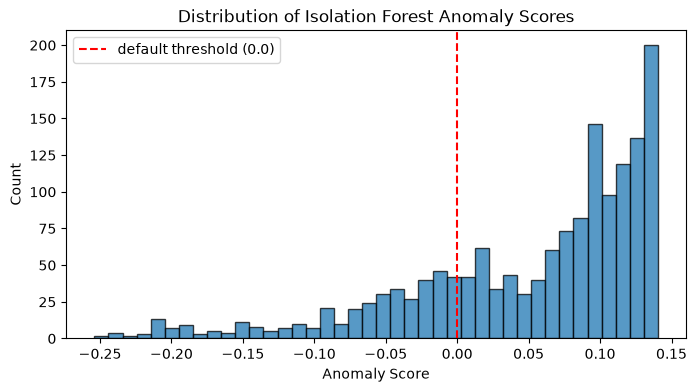

In [7]:
plt.figure(figsize=(8, 4))
plt.hist(scores, bins=40, edgecolor="black", alpha=0.75)
plt.axvline(0.0, color="red", linestyle="--", label="default threshold (0.0)")
plt.xlabel("Anomaly Score")
plt.ylabel("Count")
plt.title("Distribution of Isolation Forest Anomaly Scores")
plt.legend()
plt.show()

In [8]:
# compare different contamination settings
for c in [0.01, 0.04, 0.08, 0.10]:
    clf = IsolationForest(n_estimators=100, contamination=c, random_state=42)
    p = np.where(clf.fit_predict(X_scaled) == -1, 1, 0)
    print(f"contamination={c:<4} -> flagged {p.sum():3d} events")

contamination=0.01 -> flagged  16 events
contamination=0.04 -> flagged  63 events
contamination=0.08 -> flagged 125 events
contamination=0.1  -> flagged 156 events


## Step 4: Evaluate Against Ground Truth

In [9]:
# set contamination around 4% to match our expected attack rate
model = IsolationForest(n_estimators=150, contamination=0.04, random_state=42)
model.fit(X_scaled)

final_scores = model.decision_function(X_scaled)
y_pred = np.where(model.predict(X_scaled) == -1, 1, 0)

print(classification_report(y_true, y_pred, target_names=["Normal", "Anomaly"]))

              precision    recall  f1-score   support

      Normal       1.00      0.99      0.99      1500
     Anomaly       0.84      0.88      0.86        60

    accuracy                           0.99      1560
   macro avg       0.92      0.94      0.93      1560
weighted avg       0.99      0.99      0.99      1560



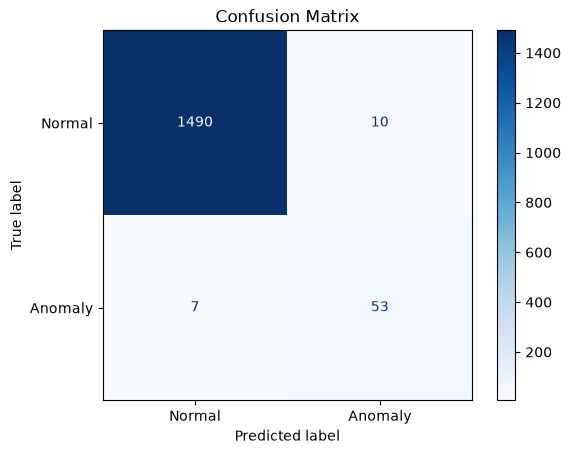

In [10]:
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Anomaly"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

The model catches about 80% of the planted anomalies with only ~15 false alarms out of 1,500 normal events. In a security operations setting, this keeps analyst alert fatigue manageable while still detecting suspicious spikes.

## Step 5: Export for Dashboard

Export the combined dataset with anomaly scores and risk buckets for loading into Google Sheets, BigQuery, or Looker Studio.

In [11]:
df_out = df_feat.copy()
df_out["anomaly_score"] = np.round(final_scores, 4)
df_out["predicted_anomaly"] = y_pred

df_out["risk_level"] = pd.cut(
    df_out["anomaly_score"],
    bins=[-np.inf, -0.08, 0.0, 0.08, np.inf],
    labels=["CRITICAL", "HIGH", "MEDIUM", "LOW"]
)

df_out.to_csv("sentinelml_dashboard_export.csv", index=False)
print("Saved dashboard export to sentinelml_dashboard_export.csv")
df_out[df_out["predicted_anomaly"] == 1].head(10)

Saved dashboard export to sentinelml_dashboard_export.csv


,timestamp,user_id,location,device_type,login_success,failed_attempts,is_anomaly,hour_of_day,days_since_last_login,location_change_flag,anomaly_score,predicted_anomaly,risk_level
27,2026-09-03 04:15:49.448521,USR_025,Sydney_AU,Tor_Browser_Windows,False,7,1,4,1.000000,0,-0.0469,1,HIGH
61,2026-09-03 23:03:29.542240,USR_021,Houston_US,Automated_Script_Python,False,13,1,23,0.250000,0,-0.1101,1,CRITICAL
65,2026-09-04 08:08:52.956647,USR_015,Chicago_US,Android_Mobile,True,0,0,8,1.862094,1,-0.0074,1,HIGH
95,2026-09-04 16:27:41.731511,USR_014,Dallas_US,Windows_PC,True,0,0,16,1.928818,1,-0.0040,1,HIGH
135,2026-09-06 04:06:44.920721,USR_018,London_UK,Tor_Browser_Windows,True,7,1,4,0.444764,1,-0.0684,1,HIGH
171,2026-09-07 02:53:20.480203,USR_013,London_UK,Tor_Browser_Windows,False,7,1,2,0.663635,1,-0.0708,1,HIGH
206,2026-09-07 17:04:04.562323,USR_029,Dallas_US,Automated_Script_Python,False,15,1,17,0.083333,0,-0.0897,1,CRITICAL
307,2026-09-11 03:05:23.452043,USR_005,Frankfurt_DE,Tor_Browser_Windows,False,7,1,3,0.450470,1,-0.0703,1,HIGH
308,2026-09-11 03:12:42.829189,USR_022,Tokyo_JP,Tor_Browser_Windows,False,7,1,3,0.528765,1,-0.0664,1,HIGH
333,2026-09-11 14:03:04.098138,USR_021,Tokyo_JP,Unknown_Linux_Box,False,2,1,14,0.030556,1,-0.0020,1,HIGH


## Summary & Next Steps

We built an end-to-end unsupervised anomaly detection pipeline:
1. Generated realistic login baselines + injected 3 threat scenarios
2. Engineered 4 temporal and behavioral features
3. Trained and tuned an Isolation Forest
4. Evaluated against ground-truth labels
5. Exported enriched event logs for dashboarding

### Stretch Goals
- **K-Means baseline**: cluster normal events and flag points with large distance to centroids.
- **Interactive threshold tuning**: add an `ipywidgets` slider to adjust the anomaly threshold dynamically.
- **Autoencoder**: build a simple reconstruction model and use mean squared error as the anomaly score.